<a href="https://colab.research.google.com/github/ardiyanto-ops/Tugas-Praktikum-Machine-Learning/blob/main/Bab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report

In [ ]:
from google.colab import files
uploaded = files.upload()
PATH = list(uploaded.keys())[0]
raw = pd.read_csv(PATH)

# Pembersihan dasar
raw = raw.drop(columns=["customerID"])
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"], errors="coerce")

# Encode kategorikal, target Churn -> 1/0
df = pd.get_dummies(raw.drop(columns=["Churn"]), drop_first=True).astype(float)
df["target"] = (raw["Churn"] == "Yes").astype(int)
fitur_cols = [c for c in df.columns if c != "target"]

print("Ukuran data:", df.shape)
print(df["target"].value_counts())

# Simulasikan missing values (hanya di kolom fitur, target tidak diganggu)
rng = np.random.default_rng(42)
mask = pd.DataFrame(rng.random((len(df), len(fitur_cols))) < 0.05,
                    columns=fitur_cols)
df_missing = df.copy()
df_missing[fitur_cols] = df[fitur_cols].mask(mask)
print(df_missing.isnull().sum())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Ukuran data: (7043, 31)
target
0    5174
1    1869
Name: count, dtype: int64
SeniorCitizen                            347
tenure                                   358
MonthlyCharges                           347
TotalCharges                             346
gender_Male                              326
Partner_Yes                              352
Dependents_Yes                           335
PhoneService_Yes                         319
MultipleLines_No phone service           351
MultipleLines_Yes                        351
InternetService_Fiber optic              344
InternetService_No                       362
OnlineSecurity_No internet service       356
OnlineSecurity_Yes                       345
OnlineBackup_No internet service         342
OnlineBackup_Yes                         368
DeviceProtection_No internet service     375
DeviceProtection_Yes                     373
TechSupport_No internet servi

In [ ]:
# Imputasi dengan KNN Imputer (hanya pada kolom fitur)
imputer = KNNImputer(n_neighbors=5)
df_imputed = df_missing.copy()
df_imputed[fitur_cols] = imputer.fit_transform(df_missing[fitur_cols])

# Deteksi outlier dengan Isolation Forest
iso = IsolationForest(contamination=0.02, random_state=42)
df_imputed["is_outlier"] = iso.fit_predict(df_imputed[fitur_cols])
print("Jumlah outlier terdeteksi:",
      (df_imputed["is_outlier"] == -1).sum())

Jumlah outlier terdeteksi: 141


In [ ]:
X = df_imputed[fitur_cols]
y = df_imputed["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, stratify=y, random_state=42)

# Tanpa penanganan imbalance
model_base = LogisticRegression(max_iter=1000).fit(X_train,
    y_train)

# Dengan SMOTE (HANYA pada train set)
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
model_smote = LogisticRegression(max_iter=1000).fit(X_train_sm,
    y_train_sm)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

In [ ]:
for nama, model in [("Baseline (tanpa SMOTE)", model_base),
    ("Dengan SMOTE", model_smote)]:
    y_pred = model.predict(X_test)
    print(f"--- {nama} ---")
    print("Akurasi :", round(accuracy_score(y_test, y_pred), 3))
    print("F1-Score:", round(f1_score(y_test, y_pred), 3))

--- Baseline (tanpa SMOTE) ---
Akurasi : 0.794
F1-Score: 0.574
--- Dengan SMOTE ---
Akurasi : 0.733
F1-Score: 0.605


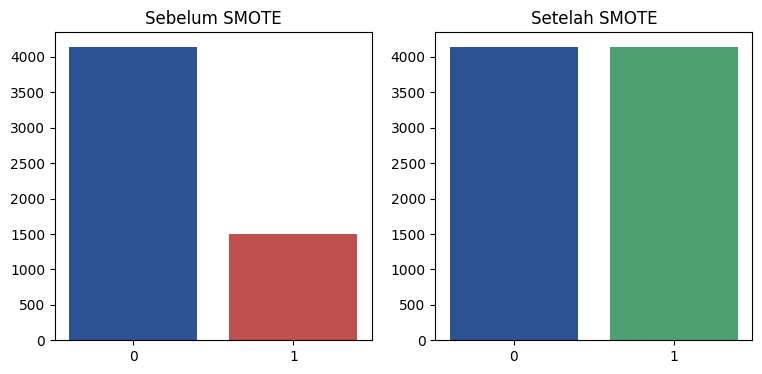

In [ ]:
import matplotlib.pyplot as plt
before = y_train.value_counts()
after = pd.Series(y_train_sm).value_counts()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(before.index.astype(str), before.values,
    color=["#2E5395", "#C0504D"])
axes[0].set_title("Sebelum SMOTE")
axes[1].bar(after.index.astype(str), after.values,
    color=["#2E5395", "#4C9F70"])
axes[1].set_title("Setelah SMOTE")
plt.show()

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
model_rus = LogisticRegression(max_iter=1000).fit(X_train_rus,
    y_train_rus)

model_cw = LogisticRegression(max_iter=1000,
    class_weight="balanced").fit(X_train, y_train)

# Bandingkan F1-Score keempat pendekatan
hasil = []
for nama, m in [("Baseline", model_base), ("SMOTE", model_smote),
                ("Undersampling", model_rus), ("class_weight", model_cw)]:
    y_pred = m.predict(X_test)
    hasil.append({"Pendekatan": nama,
                  "Akurasi": round(accuracy_score(y_test, y_pred), 3),
                  "F1-Score": round(f1_score(y_test, y_pred), 3)})
pd.DataFrame(hasil)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

,Pendekatan,Akurasi,F1-Score
0,Baseline,0.794,0.574
1,SMOTE,0.733,0.605
2,Undersampling,0.738,0.609
3,class_weight,0.733,0.607


In [ ]:
def latih_dan_f1(df_hasil_imputasi):
    Xi = df_hasil_imputasi[fitur_cols]
    yi = df_hasil_imputasi["target"]
    Xtr, Xte, ytr, yte = train_test_split(Xi, yi,
        test_size=0.2, stratify=yi, random_state=42)
    m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    return f1_score(yte, m.predict(Xte))

# (a) Mean imputation
df_mean = df_missing.copy()
df_mean[fitur_cols] = SimpleImputer(strategy="mean").fit_transform(
    df_missing[fitur_cols])

# (b) KNN Imputer (sudah dibuat di Cell 3)
print("F1 Mean Imputation:", round(latih_dan_f1(df_mean), 3))
print("F1 KNN Imputer    :", round(latih_dan_f1(df_imputed), 3))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


F1 Mean Imputation: 0.579
F1 KNN Imputer    : 0.574


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
